# README – Carga de archivos

Para realizar la prueba del modelo con nuestros propios dígitos manuscritos (del 0 al 9), es necesario cargar las imágenes directamente en el directorio raíz de Google Colab (`/content`).  
**No deben estar dentro de carpetas.**

---

##  Formato requerido de las imágenes

Cada archivo debe cumplir:

- Nombre del archivo:  
  `0.png`, `1.png`, `2.png`, …, `9.png`
- Resolución: **cualquier tamaño** (la red las redimensiona a 28×28)
- Modo: **escala de grises** (si está en RGB, se convierte automáticamente)
- Fondo preferido: **negro**
- Número preferido: **blanco o gris claro**, similar al estilo MNIST
- Formato recomendado: `.png`

Si el número está invertido (blanco sobre negro), el preprocesamiento lo detectará y corregirá automáticamente.

---

##  Cómo subirlos en Google Colab

1. En el panel izquierdo, abrir **Files**.  
2. Hacer clic en **Upload**.  
3. Subir los archivos `0.png` a `9.png`.  
4. Verificar que queden así:

```
/content/0.png  
/content/1.png  
/content/2.png  
...
/content/9.png
```

---

##  Cómo funciona el pipeline

- Detecta automáticamente cada archivo del 0 al 9.
- Preprocesa la imagen (grayscale, resize, normalización, inversión si es necesaria).
- Muestra la imagen normalizada.
- Genera un **mapa de calor**.
- Calcula la **predicción** del modelo.
- Muestra un **gráfico de barras de probabilidades**.
- Calcula el **accuracy total** sobre los 10 dígitos personalizados.

Si algún archivo no existe, el sistema lo indicará y continuará con el resto.



In [19]:
import numpy as np
import matplotlib.pyplot as plt
import cv2
import os

from tensorflow.keras.models import load_model

plt.rcParams["figure.figsize"] = (4, 4)

model = load_model("mnist_model_produccion.h5")
print("Modelo cargado correctamente.")


Modelo cargado correctamente.


In [20]:
def preprocesar_imagen(path, mostrar_etapas=False):
    """
    Preprocesa una imagen para MNIST:
    - Grayscale
    - Resize 28x28
    - Normalización
    - Inversión automática si el fondo es claro
    Devuelve:
      img_norm (28x28)
      img_flat (1,784)
    """
    img_gray = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    if img_gray is None:
        raise ValueError(f"No se pudo leer la imagen: {path}")

    img_resized = cv2.resize(img_gray, (28, 28), interpolation=cv2.INTER_AREA)
    img_norm = img_resized.astype("float32") / 255.0

    # Fondo muy claro → invertimos
    invertir = img_norm.mean() > 0.5
    if invertir:
        img_norm = 1 - img_norm

    img_flat = img_norm.reshape(1, -1)

    if mostrar_etapas:
        fig, axs = plt.subplots(1, 3, figsize=(10, 3))

        axs[0].imshow(img_gray, cmap="gray")
        axs[0].set_title("Original")
        axs[0].axis("off")

        axs[1].imshow(img_resized, cmap="gray")
        axs[1].set_title("28x28")
        axs[1].axis("off")

        hm = axs[2].imshow(img_norm, cmap="hot")
        axs[2].set_title("Normalizada")
        axs[2].axis("off")

        fig.colorbar(hm, ax=axs[2], shrink=0.8)
        plt.suptitle(f"Invertida automáticamente: {invertir}")
        plt.show()

    return img_norm, img_flat



Procesando: 0.png


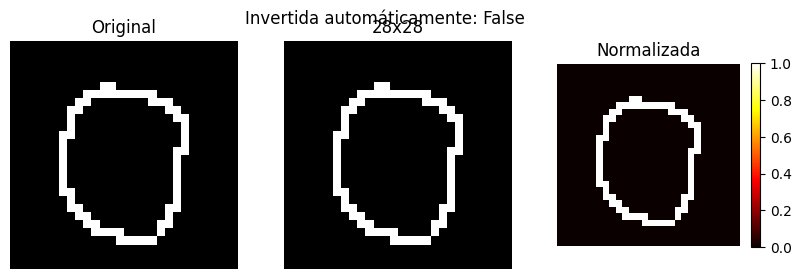

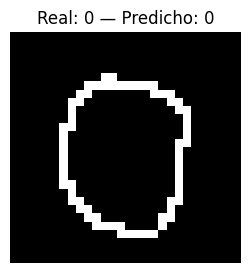

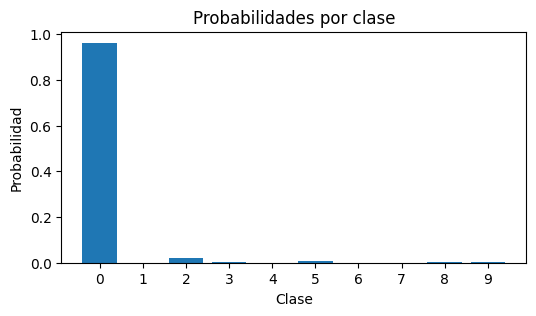


Procesando: 1.png


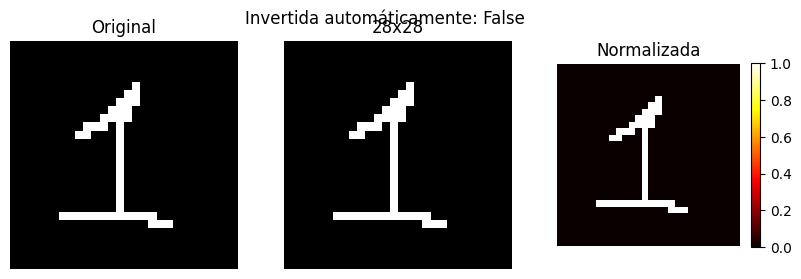

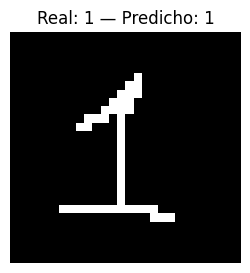

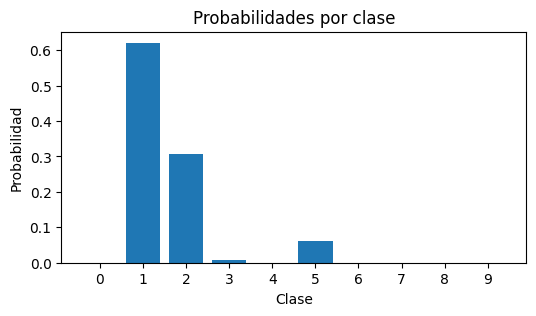


Procesando: 2.png


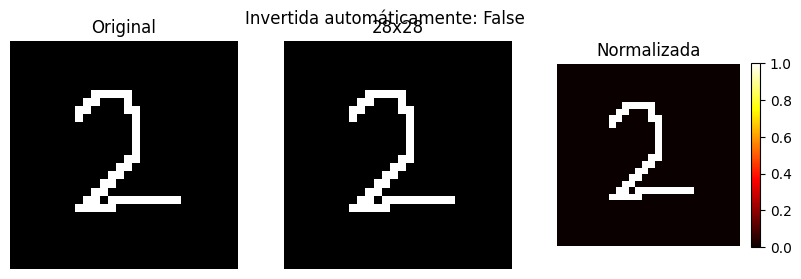

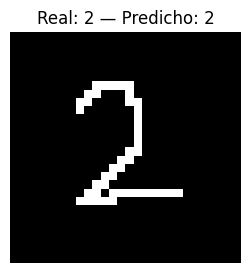

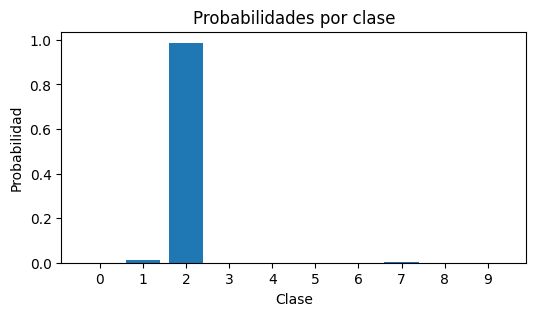


Procesando: 3.png


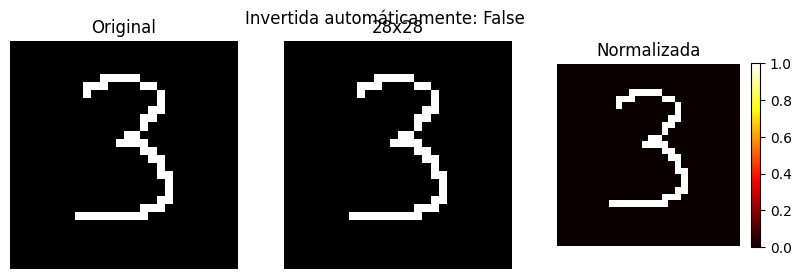

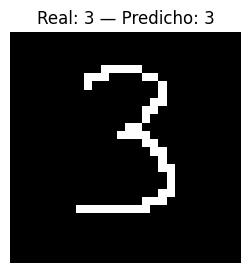

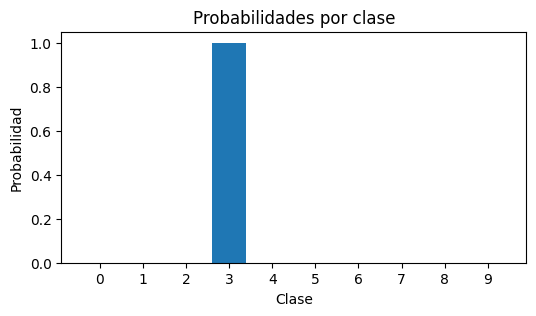


Procesando: 4.png


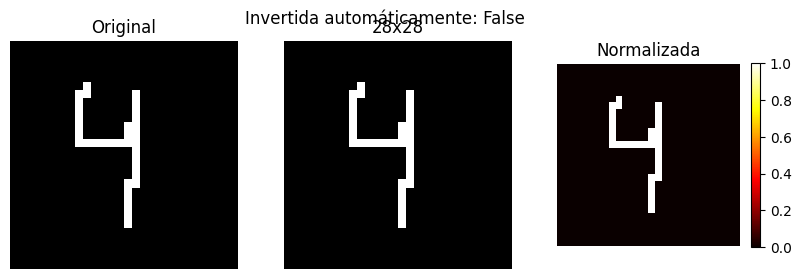

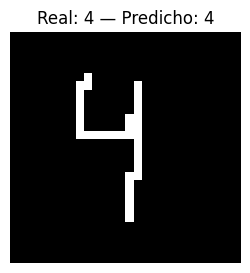

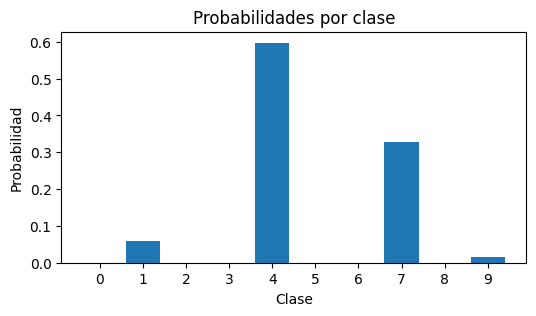


Procesando: 5.png


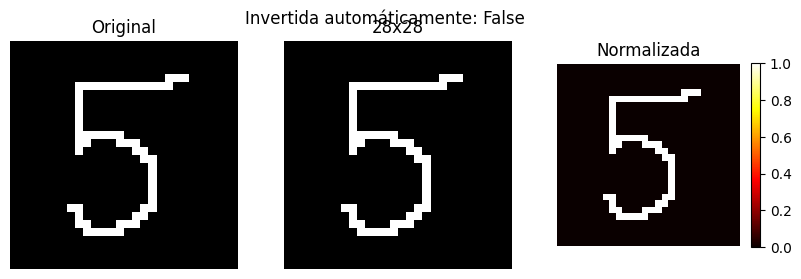

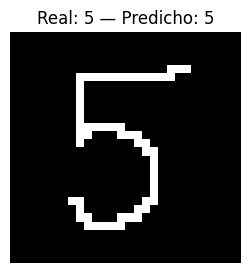

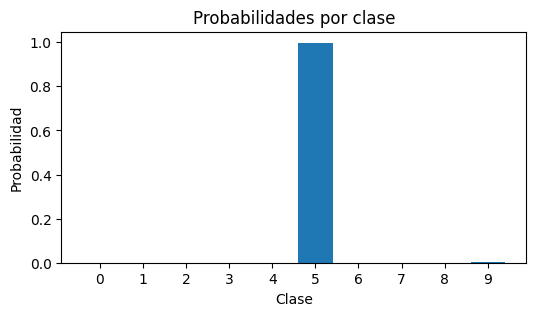


Procesando: 6.png


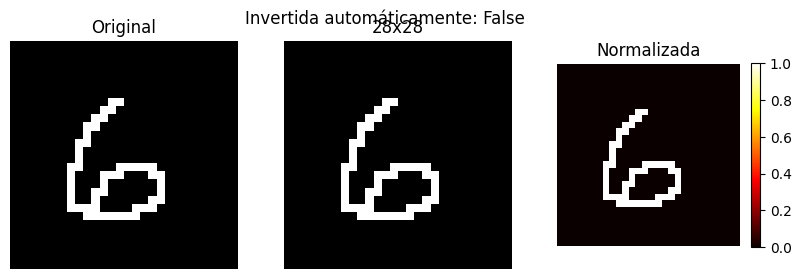

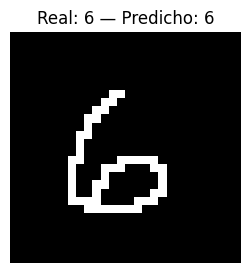

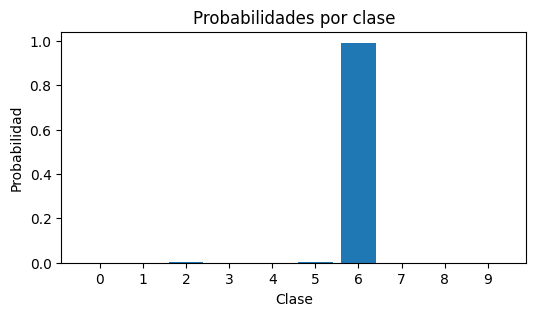


Procesando: 7.png


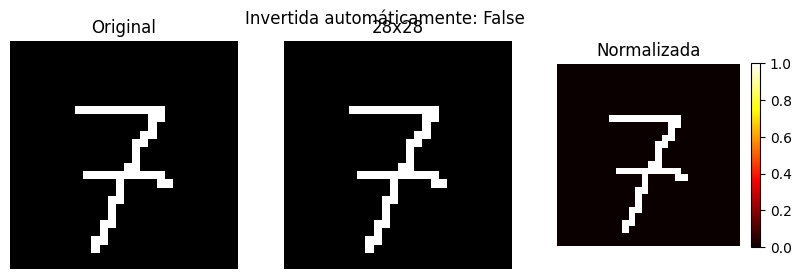

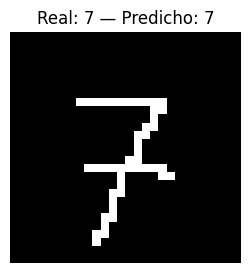

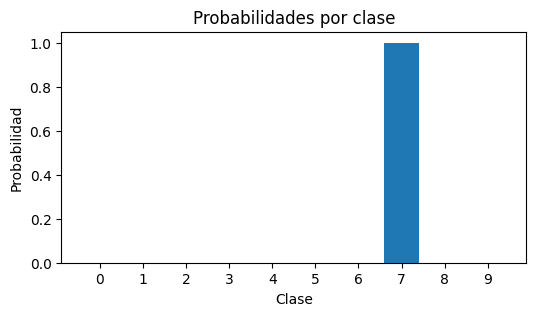


Procesando: 8.png


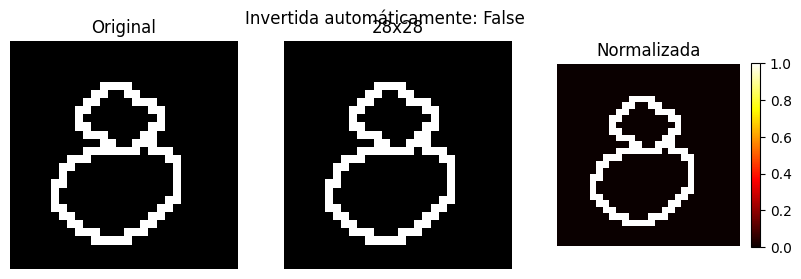

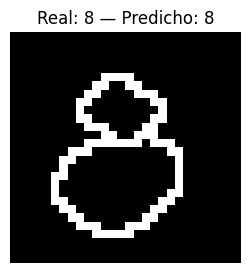

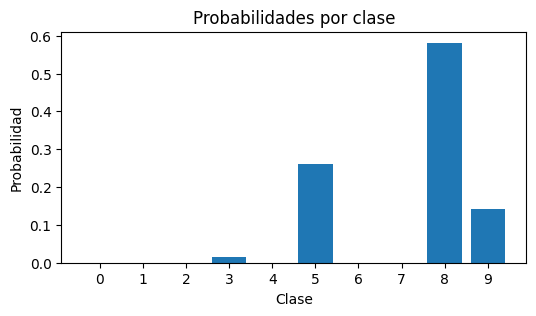


Procesando: 9.png


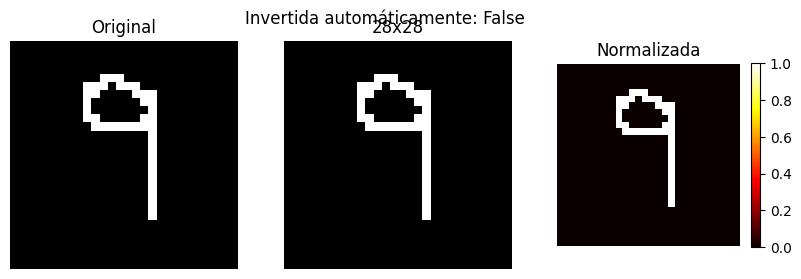

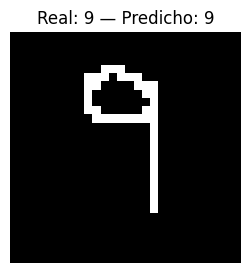

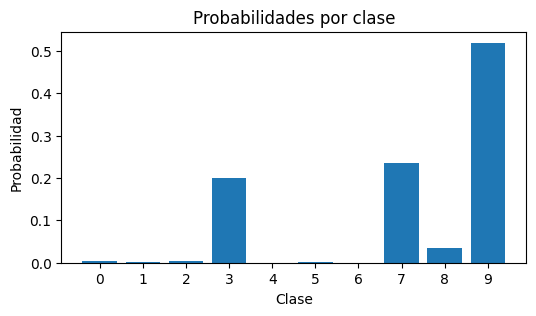

In [21]:
resultados = []

for digito in range(10):
    img_path = f"/content/{digito}.png"

    print("\n========================")
    print(f"Procesando: {digito}.png")
    print("========================")

    if not os.path.exists(img_path):
        print(f"ARCHIVO NO ENCONTRADO → {img_path}  (lo salto)")
        continue

    # Preprocesamiento
    img_norm, img_flat = preprocesar_imagen(img_path, mostrar_etapas=True)

    # Predicción
    pred_proba = model.predict(img_flat, verbose=0)
    pred = int(np.argmax(pred_proba))
    conf = float(np.max(pred_proba))

    resultados.append({
        "archivo": f"{digito}.png",
        "verdadero": digito,
        "predicho": pred,
        "confianza": conf,
        "probas": pred_proba[0]
    })

    # Mostrar imagen normalizada
    plt.figure(figsize=(3, 3))
    plt.imshow(img_norm, cmap="gray")
    plt.title(f"Real: {digito} — Predicho: {pred}")
    plt.axis("off")
    plt.show()

    # Gráfico de barras
    plt.figure(figsize=(6, 3))
    plt.bar(range(10), pred_proba[0])
    plt.xticks(range(10))
    plt.title("Probabilidades por clase")
    plt.xlabel("Clase")
    plt.ylabel("Probabilidad")
    plt.show()


In [22]:
print("\n===== RESUMEN FINAL =====\n")

correctos = 0
for r in resultados:
    ok = "✔️" if r["predicho"] == r["verdadero"] else "❌"
    print(f"{ok} {r['archivo']} — real={r['verdadero']}, pred={r['predicho']}, confianza={r['confianza']:.3f}")

    if r["predicho"] == r["verdadero"]:
        correctos += 1

accuracy = correctos / len(resultados) if resultados else 0
print(f"\nAccuracy total (0–9 propios): {accuracy:.4f}\n")



===== RESUMEN FINAL =====

✔️ 0.png — real=0, pred=0, confianza=0.963
✔️ 1.png — real=1, pred=1, confianza=0.621
✔️ 2.png — real=2, pred=2, confianza=0.987
✔️ 3.png — real=3, pred=3, confianza=1.000
✔️ 4.png — real=4, pred=4, confianza=0.598
✔️ 5.png — real=5, pred=5, confianza=0.998
✔️ 6.png — real=6, pred=6, confianza=0.992
✔️ 7.png — real=7, pred=7, confianza=1.000
✔️ 8.png — real=8, pred=8, confianza=0.581
✔️ 9.png — real=9, pred=9, confianza=0.519

Accuracy total (0–9 propios): 1.0000



#  Modelo de Producción

Después del entrenamiento del modelo final sobre MNIST, se guardó el modelo como un archivo listo para ser utilizado en producción:

```
mnist_model_produccion.h5
```

La segunda parte del trabajo consiste en emplear este modelo para predecir **dígitos manuscritos propios**, subidos manualmente al entorno de Google Colab.

---

##  1. Objetivo del Modelo de Producción

El objetivo es verificar si la red neuronal es capaz de:

- Generalizar a ejemplos **fuera del dataset MNIST**.  
- Reconocer números escritos a mano por el propio usuario.  
- Mantener un rendimiento razonable ante distintas formas y estilos de escritura.

Esta es una simulación realista del uso del modelo en un entorno productivo.

---

##  2. Preprocesamiento de las Imágenes Propias

Cada imagen (`0.png` a `9.png`) pasa por un pipeline de preprocesamiento que garantiza compatibilidad con MNIST:

1. **Conversión a escala de grises**  
2. **Redimensionamiento a 28×28 píxeles**  
3. **Normalización a valores [0,1]**  
4. **Inversión automática** si el fondo está demasiado claro  
   (MNIST utiliza fondo negro y dígito claro)
5. **Aplanamiento a vector de 784 dimensiones**

Este paso estandariza cualquier imagen externa para que pueda ser entendida por el modelo.

---

##  3. Visualizaciones Generadas

Para cada número se produce:

- Visualización de la imagen original.
- Imagen 28×28 reescalada.
- Imagen normalizada.
- **Mapa de calor**, que resalta las áreas donde el modelo ve mayor intensidad.
- Gráfico de barras con la **distribución de probabilidades** por clase.

Estas visualizaciones sirven para interpretar cómo “ve” la imagen el modelo.

---

##  4. Predicción del Modelo

Para cada dígito se obtiene:

```
- Predicción final (0 a 9)
- Probabilidad asociada
- Distribución completa de probabilidades
```

Luego se calcula un **accuracy total** sobre los 10 dígitos cargados personalmente por el usuario.

---

##  5. Interpretación de los Resultados

Los resultados permiten:

- Analizar la capacidad del modelo para reconocer escritura manual fuera de MNIST.
- Evaluar cómo influye el trazo, contraste y alineación del dígito.
- Ver si las probabilidades muestran dudas entre clases similares (p. ej., 4 y 9).

Si la accuracy es alta, indica que el modelo **generaliza correctamente**.  
Si algunas imágenes fallan, generalmente se debe a:

- Diferencias estilísticas respecto a MNIST  
- Grosor del trazo  
- Valores de contraste  
- Número desplazado del centro  
- Ruido visual

---

##  6. Conclusión

La etapa de producción demuestra que el modelo no solo funciona en condiciones controladas (dataset MNIST), sino que también **responde adecuadamente a ejemplos reales**, pasando por un pipeline completo de preprocesamiento e interpretación visual que replica un entorno productivo realista.
